# 01 — Tokens, probabilities, losses, and gradients

**Interview priority: essential.** Prerequisite: lesson 00 and basic Python arrays.
You will turn a local string into integer IDs, inspect a tiny causal model, derive
its loss, follow a gradient, and run a controlled learning-rate experiment.
No checkpoint, dataset, network access, or previous notebook artifact is required.

**Input → output:** synthetic token sequences → updated next-token probabilities.
All embedding, attention, feed-forward, normalization, and output parameters train;
the tokenizer and generated dataset are fixed. This is a miniature next-token
**pretraining** exercise, not instruction SFT. Lesson 03 adds assistant supervision.

Study in four short sittings: (1) tokens and probabilities, (2) causal tensors and
loss, (3) gradients and updates, (4) experiments and interview practice.
Follow **predict → run → modify → explain**. A successful Run All verifies code;
it does not establish your understanding.

## 1. A bounded, reproducible setup

`QUICK_MODE` bounds work; CPU is the required default. Set `PTL_DEVICE=mps`
**before launching the kernel** only after checking this installation in lesson 00.
Changing a setting inside an already running kernel requires rerunning from here.
Introductory tensors are float32. A small numerical derivative check stays on CPU
in float64. The default workload is far smaller than the course's approximate
6–8 GB engineering ceiling; that ceiling is not a safety guarantee.

In [1]:
import gc
import math
import os
import platform
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

QUICK_MODE = os.environ.get("PTL_QUICK_MODE", "1") != "0"
REQUESTED_DEVICE = os.environ.get("PTL_DEVICE", "cpu")
assert REQUESTED_DEVICE in {"cpu", "mps"}, "This local lesson supports cpu or mps."
if REQUESTED_DEVICE == "mps":
    assert torch.backends.mps.is_available(), "MPS unavailable: choose the CPU path."
DEVICE = torch.device(REQUESTED_DEVICE)
DTYPE = torch.float32
SEED = 17
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))


def synchronize():
    if DEVICE.type == "mps":
        torch.mps.synchronize()


synchronize()
lesson_started = time.perf_counter()
print({"python": platform.python_version(), "torch": torch.__version__,
       "system": platform.system(), "machine": platform.machine(),
       "device_executed": str(DEVICE), "dtype": str(DTYPE), "quick": QUICK_MODE})

{'python': '3.12.15', 'torch': '2.15.0', 'system': 'Darwin', 'machine': 'arm64', 'device_executed': 'cpu', 'dtype': 'torch.float32', 'quick': True}


## 2. Token IDs are categories, not numerical magnitudes

A tokenizer maps text to IDs in a vocabulary of size $V$. ID 7 is not intrinsically
"larger in meaning" than ID 2. Our deliberately limited character tokenizer has
six content characters and separate beginning/end markers. Its mapping is frozen.
It round-trips **only its declared alphabet** and rejects unknown characters.
Production tokenizers often use subwords or bytes; normalization, unknown tokens,
and special-token handling can affect reversibility. Token counts depend on the
tokenizer, so cross-tokenizer perplexities are not directly comparable.

**Predict:** how many IDs will `xabcdabx` have after adding BOS and EOS?

In [2]:
VOCAB = ["<bos>", "<eos>", "a", "b", "c", "d", "x", "y"]
stoi = {token: i for i, token in enumerate(VOCAB)}
V = len(VOCAB)
BOS, EOS = stoi["<bos>"], stoi["<eos>"]


def encode(text, add_boundaries=True):
    if any(ch not in stoi or len(ch) != 1 for ch in text):
        raise ValueError("Use only the local content alphabet: a b c d x y.")
    body = [stoi[ch] for ch in text]
    return [BOS, *body, EOS] if add_boundaries else body


def decode(ids):
    return "".join(VOCAB[int(i)] for i in ids if int(i) not in (BOS, EOS))


example_ids = encode("xabcdabx")
assert decode(example_ids) == "xabcdabx"
assert BOS != EOS
print("vocabulary:", stoi)
print("IDs:", example_ids, "length:", len(example_ids))
print("rendered:", " ".join(VOCAB[i] for i in example_ids))

vocabulary: {'<bos>': 0, '<eos>': 1, 'a': 2, 'b': 3, 'c': 4, 'd': 5, 'x': 6, 'y': 7}
IDs: [0, 6, 2, 3, 4, 5, 2, 3, 6, 1] length: 10
rendered: <bos> x a b c d a b x <eos>


### Embeddings: a trainable lookup

Let $E\in\mathbb R^{V\times d}$ be the embedding table, $d$ the hidden dimension,
and $x_{b,t}$ the integer ID at batch item $b$, position $t$.
The vector is $h_{b,t}=E[x_{b,t}]+P[t]$, where $P$ is a learned position table.
Input IDs have shape `[B,T]`; hidden vectors have shape `[B,T,d]`.
A one-hot row multiplied by $E$ gives the same result as row lookup, but lookup
avoids materializing a large one-hot matrix. Repeated uses of one ID accumulate
gradient contributions into its row. No gradient is taken with respect to IDs.

In [3]:
embedding = nn.Embedding(V, 4)
lookup_ids = torch.tensor([[stoi["a"], stoi["x"]]], dtype=torch.long)
lookup = embedding(lookup_ids)
one_hot = F.one_hot(lookup_ids, num_classes=V).float()
assert torch.allclose(lookup, one_hot @ embedding.weight)
print("IDs", tuple(lookup_ids.shape), "→ vectors", tuple(lookup.shape))
print("embedding for 'a':", lookup[0, 0].detach().numpy().round(3))
del embedding, lookup, one_hot

IDs (1, 2) → vectors (1, 2, 4)
embedding for 'a': [0.211 0.133 0.252 0.383]


## 3. From logits to probabilities, by hand

A **logit** $z_j\in\mathbb R$ is an unnormalized score for vocabulary entry $j$.
At a fixed context, $p_j=\exp(z_j)/\sum_{k=1}^{V}\exp(z_k)$.
These probabilities sum to 1. Adding one constant to all logits leaves them
unchanged; compute log probabilities as
$\log p_j=z_j-\operatorname{logsumexp}(z)$ for numerical stability.
Do not compute `log(softmax(z))` when extreme scores can underflow to zero.

**Worked illustration:** the three candidate logits are `[2, 1, 0]`; target is
candidate 1 (zero-based). Predict its probability and whether increasing its
logit should decrease negative log likelihood (NLL).

In [4]:
z = torch.tensor([2.0, 1.0, 0.0], dtype=torch.float32)
log_p = z - torch.logsumexp(z, dim=0)
p = log_p.exp()
target = 1
manual_nll = -log_p[target]
api_nll = F.cross_entropy(z[None, :], torch.tensor([target]))
assert torch.allclose(manual_nll, api_nll)
assert torch.allclose(p.sum(), torch.tensor(1.0))
print("probabilities:", p.numpy().round(4))
print("target probability:", round(p[target].item(), 4),
      "NLL:", round(manual_nll.item(), 4), "nats")
print("large-logit stable log probabilities:",
      F.log_softmax(torch.tensor([1000.0, 999.0, -1000.0]), dim=-1).tolist())

probabilities: [0.6652 0.2447 0.09  ]
target probability: 0.2447 NLL: 1.4076 nats
large-logit stable log probabilities: [-0.31326165795326233, -1.31326162815094, -2000.313232421875]


### Autoregressive probability and perplexity

For a sequence $x_1,\ldots,x_T$ conditioned on BOS,
$p_\theta(x_{1:T}\mid\mathrm{BOS})=\prod_{t=1}^{T}
p_\theta(x_t\mid\mathrm{BOS},x_{<t})$.
Here $\theta$ denotes all trainable model parameters. Multiplication becomes a
sum in log space. Mean token NLL is $L=-\frac1T\sum_t\log p_\theta(x_t\mid x_{<t})$;
perplexity is $\exp(L)$. Natural logarithms give **nats per token**.
A lower perplexity means better likelihood on this evaluation distribution,
tokenizer, masking, and reduction; it is not by itself evidence of helpfulness,
factual accuracy, calibration, or business value.

**Predict:** with target-token probabilities `0.5, 0.25, 0.8`, is sequence
probability their mean or their product? Does doubling sequence length leave
sequence probability unchanged even when mean token NLL is unchanged?

In [5]:
worked_probs = torch.tensor([0.5, 0.25, 0.8])  # illustrative probabilities, not a benchmark
sequence_log_probability = worked_probs.log().sum()
mean_nll = -worked_probs.log().mean()
print("product:", worked_probs.prod().item())
print("sum log probability:", sequence_log_probability.item())
print("mean NLL:", mean_nll.item(), "perplexity:", mean_nll.exp().item())
assert torch.allclose(sequence_log_probability.exp(), worked_probs.prod())

product: 0.10000000149011612
sum log probability: -2.3025851249694824
mean NLL: 0.7675283551216125 perplexity: 2.1544346809387207


## 4. A tiny causal model with visible attention

For a batch of hidden states $H$ shaped `[B,T,d]`, learned matrices
$W_Q,W_K,W_V\in\mathbb R^{d\times d}$ produce $Q,K,U$ of that same shape.
We call the value tensor $U$ here to avoid confusing it with vocabulary size $V$.
Attention is
$$A=\operatorname{softmax}_{\text{last axis}}
\left(QK^\top/\sqrt d + M\right),\qquad C=AU.$$
$A$ has shape `[B,T,T]`; its row $t$ weights **key positions** $s$.
$M_{t,s}=0$ when $s\le t$ and $-\infty$ otherwise. The mask permits attending to
the current token, but that token predicts the **next** token.
The $\sqrt d$ scaling limits score growth with dimension. Residual additions,
per-position LayerNorm, and a feed-forward network transform $C$; an output
matrix maps each final vector to $V$ logits. All these weights are trainable.

This one-block, one-head model follows causal Transformer mechanics, with learned
absolute positions. It is not OLMo: no rotary embeddings, multiple layers/heads,
large vocabulary, pretrained knowledge, or KV cache. Attention requires quadratic
`[T,T]` storage here; fused production implementations can use different storage.
This explicit implementation is small enough to inspect directly.

In [6]:
class TinyCausalLM(nn.Module):
    def __init__(self, vocab_size=V, width=24, max_length=16):
        super().__init__()
        self.width, self.max_length = width, max_length
        self.token_embedding = nn.Embedding(vocab_size, width)
        self.position_embedding = nn.Embedding(max_length, width)
        self.norm1 = nn.LayerNorm(width)
        self.q = nn.Linear(width, width, bias=False)
        self.k = nn.Linear(width, width, bias=False)
        self.v = nn.Linear(width, width, bias=False)
        self.attention_output = nn.Linear(width, width, bias=False)
        self.norm2 = nn.LayerNorm(width)
        self.ff = nn.Sequential(nn.Linear(width, 2 * width), nn.GELU(),
                                nn.Linear(2 * width, width))
        self.final_norm = nn.LayerNorm(width)
        self.lm_head = nn.Linear(width, vocab_size, bias=False)  # untied from embeddings

    def forward(self, ids, return_attention=False):
        batch_size, length = ids.shape
        assert 0 < length <= self.max_length
        positions = torch.arange(length, device=ids.device)
        h = self.token_embedding(ids) + self.position_embedding(positions)[None, :, :]
        normalized = self.norm1(h)
        q, k, values = self.q(normalized), self.k(normalized), self.v(normalized)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.width)
        future = torch.triu(torch.ones(length, length, dtype=torch.bool,
                                       device=ids.device), diagonal=1)
        scores = scores.masked_fill(future, float("-inf"))
        attention = torch.softmax(scores, dim=-1)
        h = h + self.attention_output(attention @ values)
        h = h + self.ff(self.norm2(h))
        logits = self.lm_head(self.final_norm(h))
        return (logits, attention) if return_attention else logits


torch.manual_seed(SEED)
tiny = TinyCausalLM().to(device=DEVICE, dtype=DTYPE)
ids = torch.tensor([example_ids], dtype=torch.long, device=DEVICE)
with torch.inference_mode():
    logits, attention = tiny(ids, return_attention=True)
    embedded = tiny.token_embedding(ids)
print("IDs", tuple(ids.shape), "embeddings", tuple(embedded.shape),
      "attention", tuple(attention.shape), "logits", tuple(logits.shape))
print("trainable parameters:", sum(p.numel() for p in tiny.parameters() if p.requires_grad))
print("last-position attention:", attention[0, -1].cpu().numpy().round(3))
assert torch.count_nonzero(torch.triu(attention[0], diagonal=1)).item() == 0
assert torch.allclose(attention.sum(-1), torch.ones_like(attention.sum(-1)))

IDs (1, 10) embeddings (1, 10, 24) attention (1, 10, 10) logits (1, 10, 8)
trainable parameters: 5592
last-position attention: [0.138 0.063 0.202 0.056 0.114 0.047 0.108 0.075 0.11  0.087]


### Test the causal claim

**Predict:** if we change only the final input token, which output positions
may change? Earlier positions share the same prefix and must remain unchanged
within floating-point tolerance. Deterministic architecture and evaluation mode
make this comparison meaningful; dropout would otherwise confound the check.

In [7]:
tiny.eval()
changed_ids = ids.clone()
changed_ids[0, -1] = stoi["y"]
with torch.inference_mode():
    original_logits = tiny(ids)
    changed_logits = tiny(changed_ids)
assert torch.allclose(original_logits[:, :-1], changed_logits[:, :-1], atol=1e-6)
assert not torch.allclose(original_logits[:, -1], changed_logits[:, -1])
print("maximum earlier-position difference:",
      (original_logits[:, :-1] - changed_logits[:, :-1]).abs().max().item())
print("last position can change:",
      (original_logits[:, -1] - changed_logits[:, -1]).abs().max().item())

maximum earlier-position difference: 0.0
last position can change: 0.5872834920883179


## 5. Teacher forcing, the causal shift, and token reductions

Training supplies the known previous tokens (**teacher forcing**) and scores all
next-token targets in parallel. The causal mask prevents access to future targets.
Inference instead feeds back the model's own generated tokens, so errors can
accumulate under a different context distribution.

For IDs `[B,T]`, we use input `ids[:,:-1]` and target `ids[:,1:]`, both `[B,T-1]`.
The model returns `[B,T-1,V]` logits. **We shift exactly once outside the loss.**
Unlike a Hugging Face causal LM supplied `labels=ids`, this custom model does
not shift internally. Copying both conventions would shift twice.

The empirical loss averages over the fixed training dataset's examples and their
token positions. With an all-one supervision mask $m_{b,t}$ here,
$$L(\theta)=-\frac{\sum_{b,t}m_{b,t}\log p_\theta(y_{b,t}\mid x_{b,\le t})}
{\sum_{b,t}m_{b,t}}.$$
$x$ and $y$ are fixed sampled data, $m$ is fixed, and only $p_\theta$ depends on
trainable parameters. The sum is over supervised target positions, including EOS.
Our fixed lengths require neither padding nor a padding attention mask. Lesson 02
adds assistant loss masks, padding masks, empty supervision, and unequal lengths.
**An attention mask controls what a token can see; a loss mask controls which
predictions contribute to the objective.** They solve different problems.

In [8]:
def token_nll(logits, targets):
    """Unreduced target NLL. Inputs are ALREADY aligned; no internal shift."""
    assert logits.shape[:-1] == targets.shape
    assert targets.dtype == torch.long
    log_probs = F.log_softmax(logits, dim=-1)
    return -log_probs.gather(dim=-1, index=targets.unsqueeze(-1)).squeeze(-1)


inputs, targets = ids[:, :-1], ids[:, 1:]
with torch.inference_mode():
    aligned_logits = tiny(inputs)
    per_token = token_nll(aligned_logits, targets)
    visible_loss = per_token.sum() / targets.numel()
    library_loss = F.cross_entropy(aligned_logits.reshape(-1, V), targets.reshape(-1))
assert torch.allclose(visible_loss, library_loss)
print("input → target → NLL")
for source, target_id, nll in zip(inputs[0].tolist(), targets[0].tolist(), per_token[0].tolist()):
    print(f"{VOCAB[source]:>5} → {VOCAB[target_id]:>5}: {nll:.3f}")
print("mean CE:", visible_loss.item(), "perplexity:", visible_loss.exp().item())
print("sequence log probability:", -per_token.sum().item())

input → target → NLL
<bos> →     x: 2.176
    x →     a: 1.631
    a →     b: 3.440
    b →     c: 1.403
    c →     d: 2.252
    d →     a: 2.070
    a →     b: 2.671
    b →     x: 1.170
    x → <eos>: 1.947
mean CE: 2.0844943523406982 perplexity: 8.04052448272705
sequence log probability: -18.760448455810547


## 6. Gradients: why the update moves a probability

For one target class $y$, $\ell=-z_y+\log\sum_j e^{z_j}$, hence
$\partial\ell/\partial z_j=p_j-\mathbf1[j=y]$.
The target's derivative is negative unless its probability is already one;
subtracting this gradient increases its logit. Competing derivatives are positive.
For parameters, the chain rule gives
$\nabla_\theta L=\sum_j(\partial L/\partial z_j)(\partial z_j/\partial\theta)$.
Shared parameters couple many predictions, so this direct-logit argument does
**not** guarantee every target probability increases after a full model update.

**Predict:** which sign should the target logit's gradient have? What happens to
target probability after a small SGD update $z\leftarrow z-\eta\nabla_z\ell$?

In [9]:
z_trainable = z.clone().requires_grad_(True)
loss_z = F.cross_entropy(z_trainable[None, :], torch.tensor([target]))
loss_z.backward()
expected_gradient = p - F.one_hot(torch.tensor(target), num_classes=3).float()
assert torch.allclose(z_trainable.grad, expected_gradient)
updated_z = z_trainable.detach() - 0.1 * z_trainable.grad
print("autograd:", z_trainable.grad.numpy().round(4))
print("p - one_hot(target):", expected_gradient.numpy().round(4))
print("target probability before/after:", p[target].item(),
      updated_z.softmax(-1)[target].item())
assert updated_z.softmax(-1)[target] > p[target]

autograd: [ 0.6652 -0.7553  0.09  ]
p - one_hot(target): [ 0.6652 -0.7553  0.09  ]
target probability before/after: 0.24472849071025848 0.27053505182266235


### Check a derivative independently, on CPU

Central finite differences approximate $f'(w)$ by
$[f(w+h)-f(w-h)]/(2h)$. Too large $h$ causes approximation error; too small causes
cancellation. We use float64 on CPU for this small diagnostic, not for training.
With logits $[2w,0]$ and target 0, the chain rule predicts
$d\ell/dw=2(p_0-1)$. This independently checks both sign and the factor from the
inner derivative. It does not prove every operation in the Transformer is correct.

In [10]:
w = torch.tensor(0.3, dtype=torch.float64, device="cpu", requires_grad=True)


def scalar_loss(weight):
    scalar_logits = torch.stack([2 * weight, torch.zeros_like(weight)])
    return torch.logsumexp(scalar_logits, dim=0) - scalar_logits[0]


scalar_loss(w).backward()
h = 1e-5
with torch.no_grad():
    finite_difference = (scalar_loss(w + h) - scalar_loss(w - h)) / (2 * h)
    analytic = 2 * (torch.sigmoid(2 * w) - 1)
assert torch.allclose(w.grad, finite_difference, atol=1e-8, rtol=1e-6)
assert torch.allclose(w.grad, analytic)
print("chain rule / autograd / finite difference:",
      analytic.item(), w.grad.item(), finite_difference.item())

chain rule / autograd / finite difference: -0.7086873875484092 -0.7086873875484092 -0.7086873875516985


## 7. From gradient descent to AdamW and clipping

SGD updates $\theta_t=\theta_{t-1}-\eta g_t$, with learning rate $\eta>0$ and
gradient $g_t$. Adam tracks moving averages, initialized to zero:
$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$
Bias corrections are $\widehat m_t=m_t/(1-\beta_1^t)$ and
$\widehat v_t=v_t/(1-\beta_2^t)$. AdamW applies the elementwise update
$$\theta_t=(1-\eta\lambda)\theta_{t-1}
-\eta\frac{\widehat m_t}{\sqrt{\widehat v_t}+\epsilon}.$$
$\beta_1,\beta_2$ set smoothing, $\epsilon$ stabilizes division, and $\lambda$ is
decoupled weight decay. It shrinks parameters separately from the adaptive gradient
term; adding an L2 penalty to the loss is generally different under Adam.
Optimizer moments are state, not trainable model weights.

**Worked illustration:** one parameter starts at 1, gradient is 0.25, learning rate
0.01, and decay 0.1. Predict the approximate first-step update before running.

In [11]:
parameter = nn.Parameter(torch.tensor([1.0]))  # tiny API check stays on CPU
parameter.grad = torch.tensor([0.25])
eta, decay, beta1, beta2, epsilon = 0.01, 0.1, 0.9, 0.999, 1e-8
m1 = (1 - beta1) * 0.25
v1 = (1 - beta2) * 0.25**2
mhat, vhat = m1 / (1 - beta1), v1 / (1 - beta2)
manual_parameter = 1.0 * (1 - eta * decay) - eta * mhat / (math.sqrt(vhat) + epsilon)
scalar_optimizer = torch.optim.AdamW([parameter], lr=eta, betas=(beta1, beta2),
                                     eps=epsilon, weight_decay=decay, foreach=False)
scalar_optimizer.step()
assert math.isclose(parameter.item(), manual_parameter, abs_tol=1e-7)
print("m, v:", m1, v1, "corrected:", mhat, vhat)
print("manual / PyTorch updated parameter:", manual_parameter, parameter.item())
del scalar_optimizer, parameter

m, v: 0.024999999999999994 6.250000000000006e-05 corrected: 0.25 0.0625
manual / PyTorch updated parameter: 0.9890000004 0.9890000224113464


### Clip the gradient, then update; reset before the next backward pass

Global norm clipping uses $g\leftarrow g\min(1,c/(\lVert g\rVert_2+\epsilon))$
for threshold $c$. It limits gradient spikes while preserving direction. It does
not guarantee a bounded Adam parameter update or prevent all divergence.
PyTorch accumulates gradients in `.grad`; `zero_grad(set_to_none=True)` prevents
unintended accumulation. Deliberate accumulation and token weighting come in 03.

**Predict:** gradient `[3,4]` has norm 5. With threshold 2, which vector remains?

In [12]:
clip_example = nn.Parameter(torch.zeros(2))
clip_example.grad = torch.tensor([3.0, 4.0])
original_norm = nn.utils.clip_grad_norm_([clip_example], max_norm=2.0, foreach=False)
print("original norm:", original_norm.item(), "clipped:", clip_example.grad.tolist())
assert torch.allclose(clip_example.grad, torch.tensor([1.2, 1.6]), atol=1e-6)
del clip_example

original norm: 5.0 clipped: [1.1999998092651367, 1.5999996662139893]


### One real model update, with intermediate checks

The ordering is `train → reset → forward → loss → backward → clip → step`.
Only the forward/loss/backward portion needs an autograd graph. Saving a loss tensor
in a history list can retain graphs; store `.item()` scalars instead.
This update teaches mechanics. Its before/after loss uses the **same batch** and
therefore measures training fit, not generalization.

In [13]:
tiny.train()
optimizer = torch.optim.AdamW(tiny.parameters(), lr=0.01, weight_decay=0.01, foreach=False)
optimizer.zero_grad(set_to_none=True)
training_logits = tiny(inputs)
training_loss = token_nll(training_logits, targets).mean()
assert torch.isfinite(training_loss)
before_loss = training_loss.item()
training_loss.backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all().item() for p in tiny.parameters())
head_gradient = tiny.lm_head.weight.grad.norm().item()
head_before = tiny.lm_head.weight.detach().clone()
preclip_norm = nn.utils.clip_grad_norm_(tiny.parameters(), max_norm=1.0, foreach=False)
optimizer.step()
with torch.inference_mode():
    after_loss = token_nll(tiny(inputs), targets).mean().item()
    head_change = (tiny.lm_head.weight - head_before).norm().item()
assert head_change > 0 and math.isfinite(after_loss)
print({"batch_loss_before": before_loss, "batch_loss_after": after_loss,
       "head_gradient_norm": head_gradient, "preclip_global_norm": preclip_norm.item(),
       "head_parameter_change_norm": head_change})
optimizer.zero_grad(set_to_none=True)
assert all(p.grad is None for p in tiny.parameters())
# Free the inspection model and its graph before the experiment.
del tiny, optimizer, training_logits, training_loss, head_before
# Earlier inference tensors are tiny, but are no longer needed either.
del logits, attention, embedded, original_logits, changed_logits, aligned_logits
_ = gc.collect()

{'batch_loss_before': 2.0844943523406982, 'batch_loss_after': 1.7024117708206177, 'head_gradient_norm': 1.7176262140274048, 'preclip_global_norm': 1.800252079963684, 'head_parameter_change_norm': 0.13856086134910583}


## 8. Training mode and gradient tracking are separate switches

`.train()`/`.eval()` change behaviors of modules such as dropout and batch norm.
`.eval()` does **not** freeze parameters or disable autograd.
`torch.no_grad()` disables recording operations for backward, while leaving module
mode unchanged. `torch.inference_mode()` adds restrictions and optimizations for
pure inference; its tensors should not be reused in later gradient-tracked work.
Our tiny LM has no dropout, so its outputs do not change just from `.eval()`.
The small dropout example below makes the distinction visible.

In [14]:
dropout = nn.Dropout(0.5)
probe = torch.ones(16, requires_grad=True)
dropout.eval()
eval_output = dropout(probe)
assert eval_output.requires_grad
assert torch.equal(eval_output, probe)
dropout.train()
with torch.no_grad():
    no_grad_output = dropout(probe)
assert not no_grad_output.requires_grad
assert dropout.training
print("eval output tracks gradients:", eval_output.requires_grad)
print("no_grad leaves dropout in training mode:", dropout.training)
print("training-mode dropout sample:", no_grad_output.tolist())
del dropout, probe, eval_output, no_grad_output

eval output tracks gradients: True
no_grad leaves dropout in training mode: True
training-mode dropout sample: [2.0, 0.0, 2.0, 2.0, 0.0, 0.0, 2.0, 2.0, 2.0, 2.0, 2.0, 0.0, 2.0, 0.0, 2.0, 0.0]


## 9. Controlled experiment: does learning rate change learning?

**Task:** after BOS and a cue (`x` or `y`), six random filler characters appear.
The model should reproduce the original cue and then EOS. It must retain context
beyond the previous token. This is an educational memory task, not language skill.
Fillers are sampled independently and uniformly from `a,b,c,d`; their next-token
uncertainty is irreducible under this generator.

**Hypothesis:** at a fixed short step budget, `lr=0.01` learns more than
`lr=0.0001`. The primary metric is mean validation token NLL, declared before
training. Cue-recall accuracy is a diagnostic because random filler NLL dominates
the average. Held constant: architecture, data, optimizer settings, step/batch
budget, initialization, and minibatch order **within each paired seed**.
We repeat with two training seeds in quick mode (three otherwise). This is still
a small experiment, not a statistical claim or broad hyperparameter search.

Validation strings are disjoint from training strings, drawn from the same grammar.
Using validation to compare learning rates means it is not an untouched final test.
A different grammar or longer delay would test a different generalization question.

In [15]:
def make_local_dataset(n_train=128, n_valid=64, seed=2026, filler_length=6):
    if not (1 <= filler_length <= 12 and n_train > 0 and n_valid > 0):
        raise ValueError("Use positive split sizes and filler length 1–12 (context bound).")
    if n_train + n_valid > 2 * 4**filler_length:
        raise ValueError("Too many unique examples requested for this filler length.")
    rng = np.random.default_rng(seed)
    seen, sequences = set(), []
    for _ in range(50 * (n_train + n_valid)):
        if len(sequences) == n_train + n_valid:
            break
        cue = str(rng.choice(["x", "y"]))
        filler = "".join(rng.choice(list("abcd"), size=filler_length))
        text = cue + filler + cue
        if text not in seen:
            seen.add(text)
            sequences.append(encode(text))
    if len(sequences) != n_train + n_valid:
        raise RuntimeError("Unique sampling budget exhausted; request fewer examples.")
    tensor = torch.tensor(sequences, dtype=torch.long)  # data stays on CPU
    return tensor[:n_train], tensor[n_train:]


train_ids, valid_ids = make_local_dataset()
assert not ({tuple(row) for row in train_ids.tolist()} &
            {tuple(row) for row in valid_ids.tolist()})
print("training / validation shapes:", tuple(train_ids.shape), tuple(valid_ids.shape))
print("one training sequence:", " ".join(VOCAB[i] for i in train_ids[0].tolist()))

training / validation shapes: (128, 10) (64, 10)
one training sequence: <bos> y a a c b b a y <eos>


### Baselines: uniform, a fitted bigram, and the known task rule

Uniform predicts every vocabulary item with probability $1/V$, yielding NLL
$\log V$. A more credible baseline counts training transitions and applies
additive smoothing: $p(j\mid i)=(n_{ij}+\alpha)/(\sum_k n_{ik}+\alpha V)$.
$n_{ij}$ counts adjacent IDs and $\alpha=1$ here. The bigram sees only the previous
token. It can model local structure cheaply but cannot reliably recall a distant
balanced cue from an independent filler. We also use a **grammar-aware rule**:
uniform cue initially, uniform fillers, copy the visible first cue at the known
answer position, then EOS. This rule is allowed to know our synthetic generator;
it does not inspect future target values. It is an honest, very strong baseline
for this artificial task, not a general language model. Its success illustrates
why a learned model may be unnecessary when the actual problem has a simple rule.

In [16]:
counts = torch.ones(V, V)  # additive-one smoothing; fitted on training only
for row in train_ids:
    for previous_id, next_id in zip(row[:-1].tolist(), row[1:].tolist()):
        counts[previous_id, next_id] += 1
bigram_probs = counts / counts.sum(dim=-1, keepdim=True)
bigram_target_probs = bigram_probs[valid_ids[:, :-1], valid_ids[:, 1:]]
bigram_nll = -bigram_target_probs.log().mean().item()
bigram_cue_predictions = bigram_probs[valid_ids[:, -3]].argmax(dim=-1)
bigram_cue_accuracy = (bigram_cue_predictions == valid_ids[:, -2]).float().mean().item()
print({"uniform_validation_nll": math.log(V), "bigram_validation_nll": bigram_nll,
       "bigram_cue_accuracy": bigram_cue_accuracy})

# At the cue-copy position, the prefix includes the first cue at position 1.
filler_length = valid_ids.shape[1] - 4  # BOS, initial cue, copied cue, EOS are the other four
grammar_probs = torch.zeros(len(valid_ids), valid_ids.shape[1] - 1, V)
grammar_probs[:, 0, [stoi["x"], stoi["y"]]] = 0.5
grammar_probs[:, 1:1 + filler_length, 2:6] = 0.25
grammar_probs[torch.arange(len(valid_ids)), -2, valid_ids[:, 1]] = 1.0
grammar_probs[:, -1, EOS] = 1.0
assert torch.allclose(grammar_probs.sum(-1), torch.ones_like(grammar_probs.sum(-1)))
grammar_target_probs = grammar_probs.gather(-1, valid_ids[:, 1:, None]).squeeze(-1)
grammar_nll = -grammar_target_probs.log().mean().item()
grammar_cue_accuracy = (valid_ids[:, 1] == valid_ids[:, -2]).float().mean().item()
print({"known_rule_validation_nll": grammar_nll,
       "known_rule_cue_accuracy": grammar_cue_accuracy})

{'uniform_validation_nll': 2.0794415416798357, 'bigram_validation_nll': 1.5683642625808716, 'bigram_cue_accuracy': 0.0}
{'known_rule_validation_nll': 1.0012125968933105, 'known_rule_cue_accuracy': 1.0}


### Bounded training loop

We construct one candidate at a time. Evaluation uses `eval()` **and**
`inference_mode()`. Curves contain detached Python numbers. For these fixed-length
examples the token mean and mean of sequence means coincide; lesson 02 shows why
this fails with unequal supervised lengths. A seed controls initialization and
batch draws; it does not promise bitwise equality across devices or PyTorch versions.

In [17]:
@torch.inference_mode()
def evaluate(model, batch_cpu):
    model.eval()
    batch = batch_cpu.to(DEVICE)
    predictions = model(batch[:, :-1])
    nll = token_nll(predictions, batch[:, 1:]).mean().item()
    # targets[:, -2] is the copied cue; final target is EOS.
    cue_accuracy = (predictions[:, -2].argmax(-1) == batch[:, -2]).float().mean().item()
    return nll, cue_accuracy


STEPS = 120 if QUICK_MODE else 240
BATCH_SIZE = 16
LEARNING_RATES = (0.0001, 0.01)
TRAINING_SEEDS = (11, 22) if QUICK_MODE else (11, 22, 33)
records, histories = [], {}
model = None
for training_seed in TRAINING_SEEDS:
    for learning_rate in LEARNING_RATES:
        # Release the previous candidate and optimizer before allocating another.
        if model is not None:
            del model
            _ = gc.collect()
        torch.manual_seed(training_seed)
        model = TinyCausalLM().to(device=DEVICE, dtype=DTYPE)
        batch_rng = torch.Generator(device="cpu").manual_seed(training_seed + 100)
        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate,
                                     weight_decay=0.01, foreach=False)
        history = [(0, *evaluate(model, valid_ids))]
        synchronize()
        run_started = time.perf_counter()
        for step in range(1, STEPS + 1):
            indices = torch.randint(len(train_ids), (BATCH_SIZE,), generator=batch_rng)
            batch = train_ids[indices].to(DEVICE)
            model.train()
            optimizer.zero_grad(set_to_none=True)
            predictions = model(batch[:, :-1])
            loss = token_nll(predictions, batch[:, 1:]).mean()
            assert torch.isfinite(loss).item(), "Non-finite training loss."
            loss.backward()
            grad_norm = nn.utils.clip_grad_norm_(model.parameters(), 1.0, foreach=False)
            assert torch.isfinite(grad_norm).item(), "Non-finite gradient norm."
            optimizer.step()
            if step % 20 == 0 or step == STEPS:
                history.append((step, *evaluate(model, valid_ids)))
        synchronize()
        seconds = time.perf_counter() - run_started
        train_nll, _ = evaluate(model, train_ids)
        valid_nll, cue_accuracy = evaluate(model, valid_ids)
        records.append({"seed": training_seed, "lr": learning_rate, "train_nll": train_nll,
                        "valid_nll": valid_nll, "cue_accuracy": cue_accuracy, "seconds": seconds})
        histories[(training_seed, learning_rate)] = history
        print(f"seed={training_seed} lr={learning_rate:g} train={train_nll:.3f} "
              f"valid={valid_nll:.3f} cue_accuracy={cue_accuracy:.3f} seconds={seconds:.2f}")
        # Remove state/graph references; retain only the final model for generation.
        optimizer.zero_grad(set_to_none=True)
        del optimizer, predictions, loss, batch

seed=11 lr=0.0001 train=2.083 valid=2.076 cue_accuracy=0.000 seconds=0.10


seed=11 lr=0.01 train=1.076 valid=1.090 cue_accuracy=0.500 seconds=0.09


seed=22 lr=0.0001 train=2.044 valid=2.054 cue_accuracy=0.000 seconds=0.10


seed=22 lr=0.01 train=1.069 valid=1.137 cue_accuracy=0.469 seconds=0.10


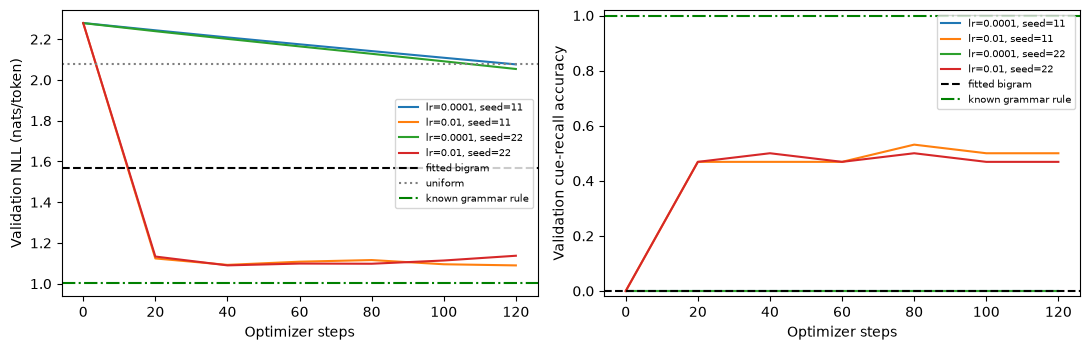

lr=0.0001: mean validation NLL=2.0650; training-seed range=[2.0537, 2.0763]
lr=0.01: mean validation NLL=1.1136; training-seed range=[1.0899, 1.1373]
paired NLL differences (0.01 minus 0.0001; negative favors 0.01): [-0.9864089488983154, -0.9164527654647827]


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for (training_seed, learning_rate), history in histories.items():
    values = np.array(history)
    label = f"lr={learning_rate:g}, seed={training_seed}"
    axes[0].plot(values[:, 0], values[:, 1], label=label)
    axes[1].plot(values[:, 0], values[:, 2], label=label)
axes[0].axhline(bigram_nll, color="black", ls="--", label="fitted bigram")
axes[0].axhline(math.log(V), color="grey", ls=":", label="uniform")
axes[0].axhline(grammar_nll, color="green", ls="-.", label="known grammar rule")
axes[0].set(ylabel="Validation NLL (nats/token)", xlabel="Optimizer steps")
axes[1].axhline(bigram_cue_accuracy, color="black", ls="--", label="fitted bigram")
axes[1].axhline(grammar_cue_accuracy, color="green", ls="-.", label="known grammar rule")
axes[1].set(ylabel="Validation cue-recall accuracy", xlabel="Optimizer steps", ylim=(-0.02, 1.02))
axes[0].legend(fontsize=7)
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()
plt.close(fig)

for learning_rate in LEARNING_RATES:
    values = [row["valid_nll"] for row in records if row["lr"] == learning_rate]
    print(f"lr={learning_rate:g}: mean validation NLL={np.mean(values):.4f}; "
          f"training-seed range=[{min(values):.4f}, {max(values):.4f}]")
paired_differences = [next(r["valid_nll"] for r in records if r["seed"] == s and r["lr"] == 0.01)
                      - next(r["valid_nll"] for r in records if r["seed"] == s and r["lr"] == 0.0001)
                      for s in TRAINING_SEEDS]
print("paired NLL differences (0.01 minus 0.0001; negative favors 0.01):", paired_differences)

### Interpret the executed output, not an expected story

First check whether both paired differences have the hypothesized sign. Then ask
whether an average hides cue errors. Inspect the gap between training and validation
NLL, compare both baselines, and read the curve rather than only the final point.
It is possible for the model to approach the grammar's NLL while still copying
cues poorly: just one of nine target positions is the copied cue. The known rule
solves cue recall exactly, so a better NLL than the bigram does not justify using
this neural model. An incorrect generated cue is a concrete failure case to inspect.
A larger learning rate may learn faster under this **fixed budget**; a longer run,
different optimizer, clipping threshold, or schedule may change the ordering.

The observed range across two training seeds is descriptive, not a confidence
interval. Evaluation uses just 64 related-grammar sequences and one fixed dataset
seed; sampling a new validation set adds another uncertainty source. Lesson 12
separates training-seed variation from evaluation uncertainty and uses appropriate
independent resampling units. No result here establishes production improvement.

**Modify:** change only `STEPS` or the filler length (use 4–12 with these split
sizes and the model's context bound). Predict which metric should change and why. Do not tune on an untouched
test set. Record your hypothesis and your actual output in the progress record.

## 10. Generation: feed predictions back, with a hard bound

Greedy decoding chooses the largest next-token logit. Sampling would draw from
the softmax distribution; a temperature $\tau>0$ uses `softmax(logits / tau)`.
Lower temperature concentrates the distribution; it does not add knowledge.
EOS is a learned category and a stopping convention. A length cap is still needed.
This model has no KV cache: each step recomputes the full prefix.

**Predict:** after the fixed six fillers, which cue should the last candidate copy?
We use a held-out prefix, evaluate the next distribution, and allow at most two
generated tokens. A single greedy sample is a debugging example, not a metric.

In [19]:
@torch.inference_mode()
def greedy_generate(model, prefix_cpu, max_new_tokens=2):
    assert 0 <= max_new_tokens <= 4, "Keep this teaching generation bounded."
    assert prefix_cpu.shape[0] == 1, "This simple decoder handles one trajectory at a time."
    model.eval()
    generated = prefix_cpu.to(DEVICE).clone()
    for _ in range(max_new_tokens):
        if generated.shape[1] >= model.max_length:
            break
        next_id = model(generated)[:, -1].argmax(-1, keepdim=True)
        generated = torch.cat([generated, next_id], dim=1)
        if torch.all(next_id == EOS).item():
            break
    return generated.cpu()


prefix = valid_ids[:1, :-2]
completion = greedy_generate(model, prefix, max_new_tokens=2)
print("prefix:", " ".join(VOCAB[i] for i in prefix[0].tolist()))
print("expected next cue and EOS:", [VOCAB[i] for i in valid_ids[0, -2:].tolist()])
print("generated:", [VOCAB[i] for i in completion[0, prefix.shape[1]:].tolist()])
print("full bounded sequence:", " ".join(VOCAB[i] for i in completion[0].tolist()))

prefix: <bos> y c a c b d b
expected next cue and EOS: ['y', '<eos>']
generated: ['x', '<eos>']
full bounded sequence: <bos> y c a c b d b x <eos>


## 11. Resource accounting and repository connection

For this float32 AdamW loop with $N$ trainable parameters, weights, gradients,
first moments, and second moments each require about $4N$ bytes once allocated.
Their sum is an **estimate** of persistent tensor storage, not process peak memory.
It excludes activations, logits, allocator/kernel workspace, Python, plots, and
optimizer temporaries. There is no additional fp32 master copy because the weights
already are fp32. Other precision and optimizer implementations differ.
MPS shares physical memory with the CPU; adding two allocator counts can double
count or omit memory, so no such sum is reported as system peak.

In [20]:
parameter_count = sum(p.numel() for p in model.parameters())
persistent_tensor_estimate = parameter_count * 4 * 4
logit_tensor_bytes = BATCH_SIZE * (train_ids.shape[1] - 1) * V * 4
synchronize()
lesson_seconds = time.perf_counter() - lesson_started
print({"parameters": parameter_count,
       "estimated_weights_gradients_adam_moments_MiB": persistent_tensor_estimate / 2**20,
       "one_training_logit_tensor_KiB": logit_tensor_bytes / 2**10,
       "measured_lesson_elapsed_seconds": round(lesson_seconds, 3),
       "executed_device": str(DEVICE)})
assert all(math.isfinite(row["valid_nll"]) for row in records)
# There is no checkpoint dependency: the entire required path recreates its data/model.
del model
_ = gc.collect()
if DEVICE.type == "mps":
    torch.mps.empty_cache()

{'parameters': 5592, 'estimated_weights_gradients_adam_moments_MiB': 0.0853271484375, 'one_training_logit_tensor_KiB': 4.5, 'measured_lesson_elapsed_seconds': 1.227, 'executed_device': 'cpu'}


The inspected original repository is described in [AUDIT.md](AUDIT.md).
This lesson extends **M1 (base-model exploration)** toward the planned M3 update.
Its source is paired with this notebook using `scripts/to_ipynb.py`.

| Concept here | Exact repository connection | Difference |
|---|---|---|
| IDs, embeddings, logits | `notebooks/m1_base_model_exploration.py`, Parts 1–4; `scripts/explore_base_model.py::inspect_tokenizer`, `inspect_model`, `inspect_embeddings`, `inspect_forward` | Original loads OLMo checkpoints; this lesson initializes a few thousand parameters locally. |
| Causal invariance | `scripts/explore_base_model.py::inspect_causality` | We use float tolerance and assert behavior rather than assuming bit equality on every backend. |
| Shifted cross-entropy | `scripts/explore_base_model.py::inspect_loss`; M1 Part 6 | Original HF model shifts internally for `labels=ids`; our visible loss shifts outside exactly once. |
| Generation | `scripts/explore_base_model.py::inspect_generation` | Original compares one base/instruct prompt; this lesson uses bounded synthetic cue recall. |
| One parameter update | `src/training/sft/__init__.py` (placeholder at audit); M3 in `PROJECT_STATUS.md` | This executable teaching loop does not imply the original repository SFT milestone is complete. |
| Reproducibility and memory | `src/utils/seed.py::set_seed`; `src/utils/memory.py::estimate` | We use local seed/config controls and explicit float32 assumptions; server CUDA estimates are a different workload. |

Historical M1 observations are about that checkpoint, tokenizer, prompt, decoding,
and recipe. Post-training **can** teach new information or skills as well as response
conventions; one base-versus-instruct answer cannot isolate the causes. Tokenizer
changes require care with embedding alignment, but adding tokens or resizing a
vocabulary is possible. We preserve the historical sources and qualify their
broad statements here.

## 12. Practice — pause before the solutions

1. **Easy comprehension:** for logits shaped `[2,9,8]`, what does each axis mean?
   Why is the target tensor `[2,9]` rather than `[2,9,8]`?
2. **Short calculation/code:** derive the gradient for target 0 under probabilities
   `[0.7,0.2,0.1]`. Then change the worked target from 1 to 0 and predict the sign
   changes before rerunning the relevant cells.
3. **Deeper debugging:** a model has excellent training loss when the causal mask
   is removed but fails at generation. Explain how the training objective became
   easier and propose an invariant that exposes the problem.

**Interview explanation:** "I implemented a small causal Transformer to trace token
IDs through embeddings, masked attention, logits, and shifted cross-entropy. I
checked the causal boundary, matched explicit NLL to PyTorch, checked a derivative,
and inspected an AdamW update. I compared learning rates with paired seeds and a
training-fitted bigram baseline. This demonstrates training mechanics on synthetic
data; it is not evidence of a production LLM quality gain."

Likely follow-ups and strong-answer points:
- **Why can training be parallel while generation is sequential?** Known prefixes,
  causal masking, teacher forcing; generated prefixes depend on earlier samples.
- **Why not pass probabilities into cross-entropy?** It expects logits, applies
  stable log-softmax, and passing probabilities changes the intended calculation.
- **Does `.eval()` prevent weight updates?** No: mode, autograd, and optimizer steps
  are separate. Explain frozen `requires_grad` parameters as another separate choice.
- **Why might lower NLL miss a bad response?** Token weighting, frequent easy tokens,
  mismatch with downstream success, distribution shift, and weak evaluation design.
- **Why not use a bigram model in production?** Sometimes you should use a simple
  model; demonstrate the need for long context or richer generalization first.

### Worked solutions — read after trying

1. Batch, prediction positions, vocabulary. Each position has one observed target
   class ID; the model supplies a distribution over eight alternatives.
2. $p-\mathrm{onehot}(0)=[-0.3,0.2,0.1]$. Subtracting a small direct-logit gradient
   increases the target logit and lowers competitors. A neural parameter update
   can couple positions, so do not extrapolate this to every individual example.
3. Without a causal mask, position $t$ can read $x_{t+1}$ while asked to predict it.
   At generation that future token is unavailable. Change a suffix token and verify
   earlier logits remain unchanged; also inspect the upper attention triangle.

**Next:** lesson 02 will audit the data path before any instruction fine-tuning:
chat boundaries, assistant labels, padding/EOS, causal shifts, and leakage.

## References and verification

- Vaswani et al., [Attention Is All You Need](https://arxiv.org/abs/1706.03762),
  especially scaled dot-product attention and decoder masking.
- Kingma & Ba, [Adam](https://arxiv.org/abs/1412.6980), moment estimates and correction.
- Loshchilov & Hutter, [Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101).
- PyTorch [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html),
  [AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html),
  [clip_grad_norm_](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.clip_grad_norm_.html),
  [Module.eval](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.eval),
  and [autograd mechanics](https://docs.pytorch.org/docs/stable/notes/autograd.html#locally-disable-grad-doc).

These are primary sources. API compatibility is checked by executing the explicit
operations above in the recorded teaching environment; the printed version is the
installed version, while the documentation's `stable` alias can change later.
See [VERIFICATION.md](VERIFICATION.md) for the session's exact CPU/MPS execution,
fresh-kernel checks, dependency versions, runtimes, and measurement limitations.